# Figures

## Colors

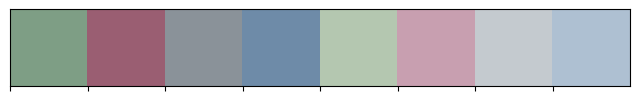

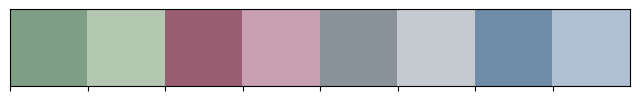

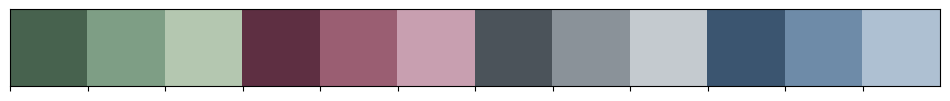

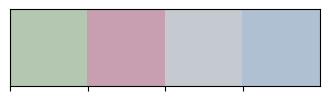

In [4]:
import seaborn as sns
# ---- paper palette (two lightest shades per family) ----------------
# families: green · red · grey · blue ; (mid, light)
paper_pal_families = {
    'green': ['#7E9E85', '#B4C7B0'],
    'red':   ['#9A5E72', '#C89FB0'],
    'grey':  ['#8A9299', '#C4CACF'],
    'blue':  ['#6E8BA8', '#AEC0D2'],
}

# palette 1 — ordered by level: all darker, then all lighter
paper_pal_level = [paper_pal_families[f][lvl]
                   for lvl in range(2)
                   for f in paper_pal_families]
# ['#7E9E85','#9A5E72','#8A9299','#6E8BA8',   # darker of the two
#  '#B4C7B0','#C89FB0','#C4CACF','#AEC0D2']   # lighter

# palette 2 — ordered by color: each family's two shades together
paper_pal_color = [c for f in paper_pal_families for c in paper_pal_families[f]]
# ['#7E9E85','#B4C7B0','#9A5E72','#C89FB0',
#  '#8A9299','#C4CACF','#6E8BA8','#AEC0D2']

sns.palplot(paper_pal_level)
sns.palplot(paper_pal_color)

paper_pal_families3 = {
    'green': ['#47624E', '#7E9E85', '#B4C7B0'],
    'red':   ['#5E2F42', '#9A5E72', '#C89FB0'],
    'grey':  ['#4B535A', '#8A9299', '#C4CACF'],   # cool slate-grey
    'blue':  ['#3B5570', '#6E8BA8', '#AEC0D2'],
}

# by color, dark -> light within each family (12 colors)
paper_pal_color3 = [c for f in paper_pal_families3 for c in paper_pal_families3[f]]
# ['#47624E','#7E9E85','#B4C7B0',   # green
#  '#5E2F42','#9A5E72','#C89FB0',   # red
#  '#4B535A','#8A9299','#C4CACF',   # grey
#  '#3B5570','#6E8BA8','#AEC0D2']   # blue

sns.palplot(paper_pal_color3)

# palette — lightest shade of each family (green · red · grey · blue)
paper_pal_light = [paper_pal_families3[f][-1] for f in paper_pal_families3]
# ['#B4C7B0', '#C89FB0', '#C4CACF', '#AEC0D2']

sns.palplot(paper_pal_light)


## Figure 2a. Single-objective benchmark

Published BindCraft designs, re-scored by funnel metadynamics and four structure
predictors. Each design is ranked against the other designs for its own target,
so ΔG and ipTM share one axis and per-target offsets drop out. Boxes are the
distribution of those ranks, points are individual designs. `AUC` is computed on
the same ranks, with a percentile bootstrap 95% CI over designs resampled within
target (4000 resamples, ranks recomputed inside each one).

27 designs: BBF-14 8, IFNAR2 9, DerF7 5, DerF21 5; 14 binder, 13 decoy.
`BBF-14_b5` and `BBF-14_b7` are excluded (His-tag at the interface). Predictors are restricted to designs that have
MD data. BBF-14 uses `BBF-14_noMSA` for ESMFold2 and `BBF-14_noMSA_template` for
the others. MD ΔG is the mean over replicas, as specified in the protocol; a
replica that does not unbind within the budget scores -100 kcal/mol.

In [5]:
# --- setup ---------------------------------------------------------------
from pathlib import Path
import numpy as np, pandas as pd
import warnings; warnings.simplefilter("ignore")
import matplotlib.pyplot as plt, seaborn as sns
import matplotlib.transforms as mtransforms
from sklearn.metrics import roc_auc_score

BENCH = Path('/Users/roessner/Documents/PostDoc/Data/260828_bindcraft_binders_reprediction')

TARGETS    = ["BBF-14", "IFNAR2", "DerF7", "DerF21"]
PREDICTORS = {"AF3": "AF3", "ESMFold2": "ESMFold2",
              "Protenix_v2": "Protenix-v2", "OpenDDE": "OpenDDE"}
METHODS    = ["MD"] + list(PREDICTORS.values())
TARGET_DIR = {"BBF-14": "BBF-14_noMSA", "IFNAR2": "IFNAR2",
              "DerF7": "DerF7", "DerF21": "DerF21"}
EXCLUDE    = {"BBF-14_b5", "BBF-14_b7"}       # His-tag at interface
N_BOOT, SEED = 4000, 0

In [6]:
# --- load ----------------------------------------------------------------
labels = []
for t in TARGETS:
    d = pd.read_csv(BENCH / f"{t}.csv").rename(columns={"Design": "design"})
    labels.append(d.assign(target=t)[["target", "design", "Type"]])
labels = pd.concat(labels, ignore_index=True)

def target_subdir(pdir, target):
    """BBF-14 was run with a template for everything except ESMFold2."""
    if target == "BBF-14" and pdir != "ESMFold2":
        return "BBF-14_noMSA_template"
    return TARGET_DIR[target]

rows = []
for pdir, pname in PREDICTORS.items():
    for t in TARGETS:
        o = pd.read_csv(BENCH / pdir / target_subdir(pdir, t) / "output.csv")
        o = (o.groupby("ID", as_index=False)["iptm"].mean()      # mean over the 3 seeds
               .rename(columns={"ID": "design"}))
        rows.append(o.assign(predictor=pname, target=t))
res = pd.concat(rows, ignore_index=True).merge(labels, on=["target", "design"], how="left")

md = pd.read_pickle(BENCH / "deltaG.pkl").rename(columns={"binder": "design"})
md["Type"]   = md["batch"].map({"binders": "binder", "decoys": "decoy"})
md["target"] = md["design"].apply(lambda s: next((t for t in TARGETS if t in s), np.nan))
md = md[np.isfinite(md["deltaG"])]
md = md.groupby(["design", "target", "Type"], as_index=False)["deltaG"].mean()

res = res[~res.design.isin(EXCLUDE)].reset_index(drop=True)
md  = md[~md.design.isin(EXCLUDE)].reset_index(drop=True)
res = res[res.design.isin(set(md["design"]))].reset_index(drop=True)   # same design set as MD

long = pd.concat([
    md.assign(method="MD", score=-md["deltaG"])[["design", "target", "Type", "method", "score"]],
    res.rename(columns={"predictor": "method"})
       .assign(score=lambda d: d["iptm"])[["design", "target", "Type", "method", "score"]],
], ignore_index=True)
long["y"]    = (long.Type == "binder").astype(int)
long["rank"] = long.groupby(["method", "target"])["score"].rank(pct=True)

long.groupby(["method", "target"]).agg(n=("y", "size"), n_binder=("y", "sum")).unstack(fill_value=0)

n                     n_binder                    
target      BBF-14 DerF21 DerF7 IFNAR2   BBF-14 DerF21 DerF7 IFNAR2
method                                                             
AF3              8      5     5      9        6      3     2      3
ESMFold2         8      5     5      9        6      3     2      3
MD               8      5     5      9        6      3     2      3
OpenDDE          8      5     5      9        6      3     2      3
Protenix-v2      8      5     5      9        6      3     2      3

In [7]:
# --- metrics -------------------------------------------------------------
def rank_auc(g):
    """AUC on within-target percentile ranks, recomputed for whatever rows are passed."""
    return roc_auc_score(g.y, g.groupby("target")["score"].rank(pct=True))

def rank_auc_ci(g, n_boot=N_BOOT, seed=SEED):
    """Percentile bootstrap: resample designs within target, recompute ranks each time."""
    rng, v = np.random.default_rng(seed), []
    for _ in range(n_boot):
        b = pd.concat([s.iloc[rng.integers(0, len(s), len(s))] for _, s in g.groupby("target")])
        if b.y.nunique() < 2:
            continue
        v.append(rank_auc(b))
    return np.percentile(v, [2.5, 97.5])

stats = pd.DataFrame([
    dict(method=m, AUC=rank_auc(long[long.method == m]),
         **dict(zip(["lo", "hi"], rank_auc_ci(long[long.method == m]))))
    for m in METHODS])
stats.round(3)

,method,AUC,lo,hi
0,MD,0.777,0.577,0.933
1,AF3,0.717,0.480,0.903
2,ESMFold2,0.511,0.265,0.733
3,Protenix-v2,0.679,0.460,0.881
4,OpenDDE,0.832,0.621,0.953


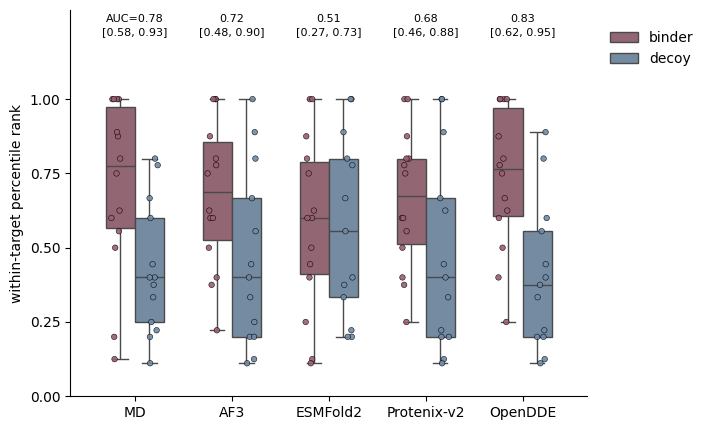

In [10]:
# --- Figure 2a -----------------------------------------------------------
PAL = {"decoy": "#6E8BA8", "binder": "#9A5E72"}   # green-mid, red-mid

kw = dict(x="method", y="rank", hue="Type", order=METHODS,
          hue_order=["binder", "decoy"], dodge=True, palette=PAL)


fig, ax = plt.subplots(figsize=(7.2, 4.4))
sns.boxplot(long, **kw, showfliers=False, width=0.6, ax=ax)
sns.stripplot(long, **kw, size=4, edgecolor="black", linewidth=0.4,
              alpha=0.9, ax=ax, legend=False)

ax.set_ylim(0, 1.30)                        # headroom for the labels
ax.set_yticks([0.0, 0.25, 0.5, 0.75, 1.0])  # but rank only goes to 1

trans = mtransforms.blended_transform_factory(ax.transData, ax.transAxes)
for i, r in stats.iterrows():
    txt = (f"AUC={r.AUC:.2f}\n[{r.lo:.2f}, {r.hi:.2f}]" if i == 0
           else f"{r.AUC:.2f}\n[{r.lo:.2f}, {r.hi:.2f}]")
    ax.text(i, 0.99, txt, transform=trans, ha="center", va="top",
            fontsize=8, linespacing=1.4)

ax.set_xlabel("")
ax.set_ylabel("within-target percentile rank")
ax.margins(x=0.08)

h, l = ax.get_legend_handles_labels()
ax.legend(h[:2], l[:2], loc="center left", bbox_to_anchor=(1.02, 0.9),
          frameon=False, title="")

sns.despine(fig)
fig.tight_layout()
plt.show()

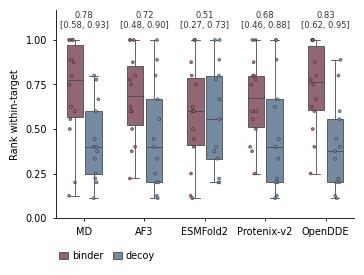

In [16]:
plt.rcParams.update({"font.size": 7, "axes.labelsize": 7, "xtick.labelsize": 7,
                     "ytick.labelsize": 7, "legend.fontsize": 7, "axes.linewidth": 0.6,
                     "xtick.major.width": 0.6, "ytick.major.width": 0.6,
                     "xtick.major.size": 2.5, "ytick.major.size": 2.5})

PAL = {"binder": "#9A5E72", "decoy": "#6E8BA8"}
kw  = dict(x="method", y="rank", hue="Type", order=METHODS,
           hue_order=["binder", "decoy"], dodge=True, palette=PAL)

fig, ax = plt.subplots(figsize=(3.5, 2.6))          # half of A4 text width
sns.boxplot(long, **kw, showfliers=False, width=0.62, gap=0.12,
            linewidth=0.6, ax=ax)
sns.stripplot(long, **kw, size=2.2, edgecolor="black", linewidth=0.25,
              alpha=0.9, ax=ax, legend=False)

ax.set_ylim(0, 1.17)
ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])

trans = mtransforms.blended_transform_factory(ax.transData, ax.transAxes)
for i, r in stats.iterrows():
    ax.text(i, 0.995, f"{r.AUC:.2f}\n[{r.lo:.2f}, {r.hi:.2f}]", transform=trans,
            ha="center", va="top", fontsize=6, linespacing=1.2, color="#333333")

ax.set_xlabel("")
ax.set_ylabel("Rank within-target")
ax.margins(x=0.04)

h, l = ax.get_legend_handles_labels()
ax.legend(h[:2], l[:2], loc="upper left", bbox_to_anchor=(0.0, -0.14), ncol=2,
          frameon=False, handlelength=0.9, handletextpad=0.4,
          columnspacing=1.0, borderaxespad=0)

sns.despine(fig)
fig.tight_layout(pad=0.3)
fig.savefig("Figure2/bindcraft_targets.svg")

## Figure 2b. Single-objective, the PD-L1 campaign

The same question as Figure 2a asked of our own designs: can a method rank
designs that bind a given target above those that do not? The unit of analysis
is the design-target pair, and a design counts as a binder for a target if it
bound that species or both. Human and mouse PD-L1 are separate strata for the
rank, then pooled.

27 designs, 54 design-target rows, 14 binders against human and 16 against
mouse. Because each design appears in both strata the rows are clustered, so the
bootstrap resamples designs rather than rows and the effective sample size is
closer to 27 than to 54.

In [25]:
# --- Figure 2b: load the campaign ----------------------------------------
CAMP     = Path('/Users/roessner/Documents/PostDoc/Data/261107_funnel_pdl1_reprediction')
CAMP_DIR = {"AF3": "AF3_repredict", "ESMFold2": "ESMFold2_repredict",
            "Protenix-v2": "Protenix-v2_repredict", "OpenDDE": "OpenDDE_repredict"}
CAMP_TARGETS = ["human", "mouse"]

anno = pd.read_csv(CAMP / 'experimental_labels.csv')

def camp_binary(df):
    """binder = bound this target (either 'both' or this species); drops 'unknown'."""
    df = df.merge(anno, how='left', on='Design')
    df = df[df.Experimental != 'unknown'].copy()
    df['Type'] = np.select(
        [df.Experimental.eq('none'),
         df.Experimental.eq('both'),
         df.Experimental.eq(df.target)],
        ['decoy', 'binder', 'binder'], default='decoy')
    return df

cmd = pd.read_pickle(CAMP / 'deltaG_labled.pkl')
cmd = cmd[cmd.Experimental != 'unknown']
cmd = cmd.groupby(['Design', 'target', 'Experimental'], as_index=False).agg(
    deltaG=('deltaG', 'mean'))                       # protocol: mean over replicas
cmd['Type'] = np.select(
    [cmd.Experimental.eq('none'),
     cmd.Experimental.eq('both'),
     cmd.Experimental.eq(cmd.target)],
    ['decoy', 'binder', 'binder'], default='decoy')
cmd = cmd.assign(method='MD', score=-cmd.deltaG)

def camp_iptm(name):
    out = []
    for t, sub in zip(CAMP_TARGETS, ['hPDL1', 'mPDL1']):
        d = pd.read_csv(CAMP / CAMP_DIR[name] / sub / 'output.csv')[['ID', 'iptm']]
        d = d.groupby('ID', as_index=False).agg(iptm=('iptm', 'mean'))   # mean over seeds
        out.append(d.rename(columns={'ID': 'Design'}).assign(target=t))
    d = pd.concat(out, ignore_index=True)
    return camp_binary(d).assign(method=name, score=lambda x: x.iptm)

ccols = ['Design', 'target', 'Experimental', 'Type', 'method', 'score']
camp = pd.concat([cmd[ccols]] + [camp_iptm(m)[ccols] for m in METHODS[1:]],
                 ignore_index=True)
camp['y']    = (camp.Type == 'binder').astype(int)
camp['rank'] = camp.groupby(['method', 'target'])['score'].rank(pct=True)

camp.groupby(['method', 'target']).agg(n=('y', 'size'), n_binder=('y', 'sum')).unstack(fill_value=0)

n       n_binder      
target      human mouse    human mouse
method                                
AF3            27    27       14    16
ESMFold2       27    27       14    16
MD             27    27       14    16
OpenDDE        27    27       14    16
Protenix-v2    27    27       14    16

In [26]:
# --- Figure 2b: metrics ---------------------------------------------------
def camp_rank_auc(g):
    """AUC on within-target percentile ranks, recomputed for whatever rows are passed."""
    return roc_auc_score(g.y, g.groupby('target')['score'].rank(pct=True))

def camp_rank_auc_ci(g, n_boot=N_BOOT, seed=SEED):
    """Bootstrap over DESIGNS, since each design appears in both species strata."""
    rng       = np.random.default_rng(seed)
    designs   = g.Design.unique()
    by_design = {d: sub for d, sub in g.groupby('Design')}
    v = []
    for _ in range(n_boot):
        b = pd.concat([by_design[d] for d in rng.choice(designs, len(designs), replace=True)])
        if b.y.nunique() < 2:
            continue
        v.append(camp_rank_auc(b))
    return np.percentile(v, [2.5, 97.5])

camp_stats = pd.DataFrame([
    dict(method=m, AUC=camp_rank_auc(camp[camp.method == m]),
         **dict(zip(['lo', 'hi'], camp_rank_auc_ci(camp[camp.method == m]))))
    for m in METHODS])

display(camp_stats.round(3))

,method,AUC,lo,hi
0,MD,0.694,0.512,0.849
1,AF3,0.581,0.417,0.742
2,ESMFold2,0.708,0.565,0.840
3,Protenix-v2,0.656,0.494,0.797
4,OpenDDE,0.647,0.492,0.786


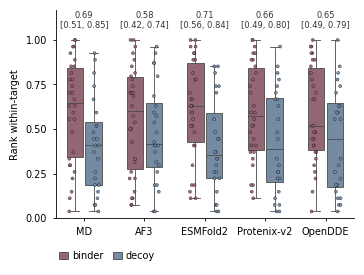

In [27]:
# --- Figure 2b ------------------------------------------------------------
plt.rcParams.update({"font.size": 7, "axes.labelsize": 7, "xtick.labelsize": 7,
                     "ytick.labelsize": 7, "legend.fontsize": 7, "axes.linewidth": 0.6,
                     "xtick.major.width": 0.6, "ytick.major.width": 0.6,
                     "xtick.major.size": 2.5, "ytick.major.size": 2.5})

PAL = {"binder": "#9A5E72", "decoy": "#6E8BA8"}
kw  = dict(x="method", y="rank", hue="Type", order=METHODS,
           hue_order=["binder", "decoy"], dodge=True, palette=PAL)

fig, ax = plt.subplots(figsize=(3.5, 2.6))          # half of A4 text width
sns.boxplot(camp, **kw, showfliers=False, width=0.62, gap=0.12,
            linewidth=0.6, ax=ax)
sns.stripplot(camp, **kw, size=2.2, edgecolor="black", linewidth=0.25,
              alpha=0.9, ax=ax, legend=False)

ax.set_ylim(0, 1.17)
ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])

trans = mtransforms.blended_transform_factory(ax.transData, ax.transAxes)
for i, r in camp_stats.iterrows():
    ax.text(i, 0.995, f"{r.AUC:.2f}\n[{r.lo:.2f}, {r.hi:.2f}]", transform=trans,
            ha="center", va="top", fontsize=6, linespacing=1.2, color="#333333")

ax.set_xlabel("")
ax.set_ylabel("Rank within-target")
ax.margins(x=0.04)

h, l = ax.get_legend_handles_labels()
ax.legend(h[:2], l[:2], loc="upper left", bbox_to_anchor=(0.0, -0.14), ncol=2,
          frameon=False, handlelength=0.9, handletextpad=0.4,
          columnspacing=1.0, borderaxespad=0)

sns.despine(fig)
fig.tight_layout(pad=0.3)
fig.savefig("Figure2/campaign_pdl1.svg")

## Supplementary Figure S1. Per-target distributions behind Figure 2a

The same 27 designs and the same scores as Figure 2a, shown per target in raw
units instead of pooled as within-target ranks. MD keeps its own ΔG axis on the
left, inverted so that more negative is upward; the four predictors share one
ipTM axis, drawn on the right-hand edge, so their spreads are directly
comparable. The number above each pair of boxes is the per-target AUC, computed
on the raw scores.

Per-target n (binder/decoy): BBF-14 6/2, IFNAR2 3/6, DerF7 2/3, DerF21 3/2.
Each per-target AUC therefore rests on 12, 18, 6 and 6 binder-decoy pairs
respectively, so the values are coarse by construction: with 6 pairs an AUC can
only take multiples of 1/6, which is why DerF21 reads 0.50 for four of the five
methods. This is the reason Figure 2a pools across targets rather than reporting
these values.

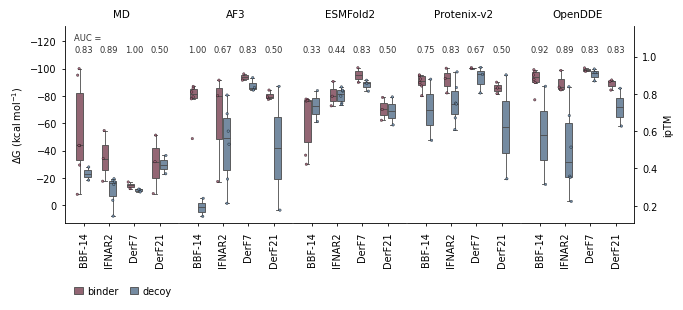

In [28]:
# --- Supplementary Figure S1: per-target, raw units ----------------------
plt.rcParams.update({"font.size": 7, "axes.labelsize": 7, "xtick.labelsize": 7,
                     "ytick.labelsize": 7, "legend.fontsize": 7, "axes.linewidth": 0.6,
                     "xtick.major.width": 0.6, "ytick.major.width": 0.6,
                     "xtick.major.size": 2.5, "ytick.major.size": 2.5})

PAL = {"binder": "#9A5E72", "decoy": "#6E8BA8"}

raw = long.copy()
raw["value"] = np.where(raw.method == "MD", -raw.score, raw.score)   # back to ΔG / ipTM

fig, axes = plt.subplots(1, len(METHODS), figsize=(6.69, 3.0))       # full A4 text width

for ax, m in zip(axes, METHODS):
    sub = raw[raw.method == m]
    kw  = dict(x="target", y="value", hue="Type", order=TARGETS,
               hue_order=["binder", "decoy"], dodge=True, palette=PAL)
    sns.boxplot(sub, **kw, showfliers=False, width=0.62, gap=0.12,
                linewidth=0.6, ax=ax)
    sns.stripplot(sub, **kw, size=1.8, edgecolor="black", linewidth=0.25,
                  alpha=0.9, ax=ax, legend=False)
    ax.set_title(m, fontsize=7.5)
    ax.set_xlabel("")
    ax.margins(x=0.12)
    if ax.legend_ is not None:
        ax.legend_.remove()
    plt.setp(ax.get_xticklabels(), rotation=90, ha="center", va="top")

axes[0].invert_yaxis()                          # more negative ΔG upward

lo = min(a.get_ylim()[0] for a in axes[1:])     # one ipTM scale across the predictors
hi = max(a.get_ylim()[1] for a in axes[1:])
for a in axes[1:]:
    a.set_ylim(lo, hi)

for ax, m in zip(axes, METHODS):                # headroom for the two annotation lines
    y0, y1 = ax.get_ylim()
    ax.set_ylim(y0, y1 + (y1 - y0) * 0.22)
    tr  = mtransforms.blended_transform_factory(ax.transData, ax.transAxes)
    sub = raw[raw.method == m]
    for i, t in enumerate(TARGETS):
        s = sub[sub.target == t]
        if s.y.nunique() < 2:
            continue
        ax.text(i, 0.90, f"{roc_auc_score(s.y, s.score):.2f}", transform=tr,
                ha="center", va="top", fontsize=6, color="#333333")

axes[0].text(0.08, 0.96, "AUC =", transform=axes[0].transAxes,
             ha="left", va="top", fontsize=6, color="#333333")

axes[0].set_ylabel(r"$\Delta$G (kcal mol$^{-1}$)")
for a in axes[1:]:
    a.set_ylabel("")

# ipTM scale on the right-hand edge; nothing in between
axes[-1].yaxis.tick_right()
axes[-1].yaxis.set_label_position("right")
axes[-1].set_ylabel("ipTM")

sns.despine(fig)                                # must run before the spine surgery below
for a in axes[1:-1]:                            # inner panels carry no y axis at all
    a.set_yticks([])
    a.spines["left"].set_visible(False)
axes[-1].spines["right"].set_visible(True)
axes[-1].spines["left"].set_visible(False)

fig.tight_layout(pad=0.3, w_pad=0.15, rect=[0, 0.12, 1, 1])

x0 = axes[0].get_position().x0                  # legend aligned with the panels
h, l = axes[0].get_legend_handles_labels()
fig.legend(h[:2], l[:2], loc="lower left", bbox_to_anchor=(x0, 0.005), ncol=2,
           frameon=False, handlelength=0.9, handletextpad=0.4, columnspacing=1.2)

plt.show()
fig.savefig("Figure2/bindcraft_campaign_per_target.svg")

## Supplementary Figure S2. Per-target distributions behind Figure 2b

The same 27 designs and the same scores as Figure 2b, shown per target in raw
units instead of pooled as within-target ranks. MD keeps its own ΔG axis on the
left, inverted so that more negative is upward; the four predictors share one
ipTM axis, drawn on the right-hand edge. The number above each pair of boxes is
the per-target AUC, computed on the raw scores.

A design counts as a binder for a target if it bound that species or both, so
the same design appears in both strata with potentially different labels: 14 of
27 bind human PD-L1 and 16 of 27 bind mouse. Unlike Supplementary Figure S1,
the x labels are horizontal, since there are two targets per panel rather than
four.

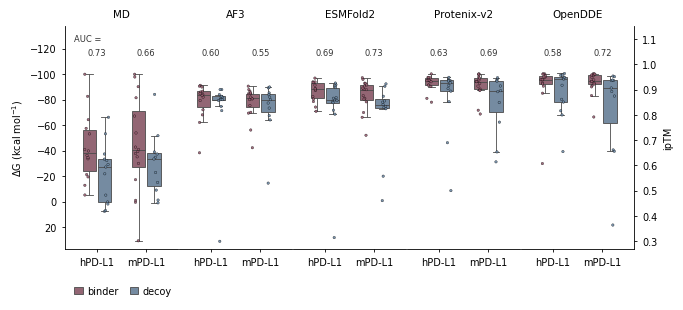

In [30]:
# --- Supplementary Figure S2: campaign per-target, raw units -------------
plt.rcParams.update({"font.size": 7, "axes.labelsize": 7, "xtick.labelsize": 7,
                     "ytick.labelsize": 7, "legend.fontsize": 7, "axes.linewidth": 0.6,
                     "xtick.major.width": 0.6, "ytick.major.width": 0.6,
                     "xtick.major.size": 2.5, "ytick.major.size": 2.5})

PAL      = {"binder": "#9A5E72", "decoy": "#6E8BA8"}
CAMP_LBL = {"human": "hPD-L1", "mouse": "mPD-L1"}

craw = camp.copy()
craw["value"] = np.where(craw.method == "MD", -craw.score, craw.score)  # back to ΔG / ipTM
craw["tlab"]  = craw.target.map(CAMP_LBL)
order = [CAMP_LBL[t] for t in CAMP_TARGETS]

fig, axes = plt.subplots(1, len(METHODS), figsize=(6.69, 3.0))       # full A4 text width

for ax, m in zip(axes, METHODS):
    sub = craw[craw.method == m]
    kw  = dict(x="tlab", y="value", hue="Type", order=order,
               hue_order=["binder", "decoy"], dodge=True, palette=PAL)
    sns.boxplot(sub, **kw, showfliers=False, width=0.62, gap=0.12,
                linewidth=0.6, ax=ax)
    sns.stripplot(sub, **kw, size=1.8, edgecolor="black", linewidth=0.25,
                  alpha=0.9, ax=ax, legend=False)
    ax.set_title(m, fontsize=7.5)
    ax.set_xlabel("")
    ax.margins(x=0.22)
    if ax.legend_ is not None:
        ax.legend_.remove()

axes[0].invert_yaxis()                          # more negative ΔG upward

lo = min(a.get_ylim()[0] for a in axes[1:])     # one ipTM scale across the predictors
hi = max(a.get_ylim()[1] for a in axes[1:])
for a in axes[1:]:
    a.set_ylim(lo, hi)

for ax, m in zip(axes, METHODS):                # headroom for the two annotation lines
    y0, y1 = ax.get_ylim()
    ax.set_ylim(y0, y1 + (y1 - y0) * 0.22)
    tr  = mtransforms.blended_transform_factory(ax.transData, ax.transAxes)
    sub = craw[craw.method == m]
    for i, t in enumerate(CAMP_TARGETS):
        s = sub[sub.target == t]
        if s.y.nunique() < 2:
            continue
        ax.text(i, 0.90, f"{roc_auc_score(s.y, s.score):.2f}", transform=tr,
                ha="center", va="top", fontsize=6, color="#333333")

axes[0].text(0.08, 0.96, "AUC =", transform=axes[0].transAxes,
             ha="left", va="top", fontsize=6, color="#333333")

axes[0].set_ylabel(r"$\Delta$G (kcal mol$^{-1}$)")
for a in axes[1:]:
    a.set_ylabel("")

# ipTM scale on the right-hand edge; nothing in between
axes[-1].yaxis.tick_right()
axes[-1].yaxis.set_label_position("right")
axes[-1].set_ylabel("ipTM")

sns.despine(fig)                                # must run before the spine surgery below
for a in axes[1:-1]:                            # inner panels carry no y axis at all
    a.set_yticks([])
    a.spines["left"].set_visible(False)
axes[-1].spines["right"].set_visible(True)
axes[-1].spines["left"].set_visible(False)

fig.tight_layout(pad=0.3, w_pad=0.15, rect=[0, 0.12, 1, 1])

x0 = axes[0].get_position().x0                  # legend aligned with the panels
h, l = axes[0].get_legend_handles_labels()
fig.legend(h[:2], l[:2], loc="lower left", bbox_to_anchor=(x0, 0.005), ncol=2,
           frameon=False, handlelength=0.9, handletextpad=0.4, columnspacing=1.2)

fig.savefig("Figure2/PDL1_campaign_per_target.svg")